In [6]:
import pandas as pd

# Fix the file path - use raw string (r"") or forward slashes
df = pd.read_csv (r"D:\Pands Python\expense_tracker.csv")
print(df)


           Date          Description  Amount       Category  Sub-Category  \
0    2026-01-01        Salary Credit  150000         Income        Salary   
1    2026-01-02    Swiggy Food Order    -450           Food    Eating Out   
2    2026-01-02  Uber Ride to Office    -280      Transport    Ride Share   
3    2026-01-03  BigBasket Groceries   -1250      Groceries    Essentials   
4    2026-01-03      Netflix Monthly    -199  Entertainment  Subscription   
..          ...                  ...     ...            ...           ...   
348  2026-06-28            Insurance   -5000      Insurance        Health   
349  2026-06-28               Coffee    -180           Food     Beverages   
350  2026-06-29               Swiggy    -530           Food    Eating Out   
351  2026-06-29       Phone Recharge    -500          Bills     Utilities   
352  2026-06-30            Groceries   -1200      Groceries    Essentials   

    Payment_Method  
0    Bank Transfer  
1              UPI  
2           

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
#set style for better visuals
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
#For inline display in jupyter
%matplotlib inline

In [13]:
print("Dataset shape :" ,df.shape)
print("\nFirst 5 row :")
df.head()

Dataset shape : (353, 6)

First 5 row :


,Date,Description,Amount,Category,Sub-Category,Payment_Method
0,2026-01-01,Salary Credit,150000,Income,Salary,Bank Transfer
1,2026-01-02,Swiggy Food Order,-450,Food,Eating Out,UPI
2,2026-01-02,Uber Ride to Office,-280,Transport,Ride Share,UPI
3,2026-01-03,BigBasket Groceries,-1250,Groceries,Essentials,Card
4,2026-01-03,Netflix Monthly,-199,Entertainment,Subscription,Card


In [14]:
#data type
print("Data Type :")
print(df.dtypes)
print("\n" + "="*50)


Data Type :
Date              object
Description       object
Amount             int64
Category          object
Sub-Category      object
Payment_Method    object
dtype: object



In [15]:
#chek for null
print("\nNull Values :")
print(df.isnull().sum())
print("\n" + "="*50)


Null Values :
Date              0
Description       0
Amount            0
Category          0
Sub-Category      0
Payment_Method    0
dtype: int64



In [27]:
#Basic Statistics
print("\nUnique Categories :", df['Category'].nunique())
print("Categories:", df['Category'].unique())
print("\nUnique Sub-Categories:", df['Sub-Category'].nunique())
print("Sub-Categories:", df['Sub-Category'].unique())
print("Payment Method:" , df['Payment_Method'].unique())


Unique Categories : 15
Categories: ['Income' 'Food' 'Transport' 'Groceries' 'Entertainment' 'Rent' 'Bills'
 'Shopping' 'Healthcare' 'Health' 'Insurance' 'Others' 'Personal Care'
 'Travel' 'EMI']

Unique Sub-Categories: 24
Sub-Categories: ['Salary' 'Eating Out' 'Ride Share' 'Essentials' 'Subscription' 'Housing'
 'Utilities' 'Fuel' 'Online' 'Beverages' 'Public Transit' 'Medicine'
 'Fitness' 'Events' 'Clothing' 'Health' 'Books' 'Gifts' 'Grooming'
 'Leisure' 'Accommodation' 'Service' 'Loan' 'Electronics']
Payment Method: ['Bank Transfer' 'UPI' 'Card']


In [29]:
df['Date'] = pd.to_datetime(df['Date'])
print(df['Date'])

0     2026-01-01
1     2026-01-02
2     2026-01-02
3     2026-01-03
4     2026-01-03
         ...    
348   2026-06-28
349   2026-06-28
350   2026-06-29
351   2026-06-29
352   2026-06-30
Name: Date, Length: 353, dtype: datetime64[ns]


In [39]:
df['Month']= df['Date'].dt.strftime('%B')
print(df['Month'])

0      January
1      January
2      January
3      January
4      January
        ...   
348       June
349       June
350       June
351       June
352       June
Name: Month, Length: 353, dtype: object


In [40]:
df['Month_Num'] = df['Date'].dt.month
print(df['Month_Num'])

0      1
1      1
2      1
3      1
4      1
      ..
348    6
349    6
350    6
351    6
352    6
Name: Month_Num, Length: 353, dtype: int32


In [41]:
df['Year'] =df['Date'].dt.year
print(df['Year'])

0      2026
1      2026
2      2026
3      2026
4      2026
       ... 
348    2026
349    2026
350    2026
351    2026
352    2026
Name: Year, Length: 353, dtype: int32


In [42]:
df['Day'] = df['Date'].dt.day
print(df['Day'])

0       1
1       2
2       2
3       3
4       3
       ..
348    28
349    28
350    29
351    29
352    30
Name: Day, Length: 353, dtype: int32


In [44]:
df['Weekday'] =df['Date'].dt.day_name()
print(df['Weekday'])

0      Thursday
1        Friday
2        Friday
3      Saturday
4      Saturday
         ...   
348      Sunday
349      Sunday
350      Monday
351      Monday
352     Tuesday
Name: Weekday, Length: 353, dtype: object


In [46]:
df['Weekday_Num'] = df['Date'].dt.weekday
print(df['Weekday_Num'])

0      3
1      4
2      4
3      5
4      5
      ..
348    6
349    6
350    0
351    0
352    1
Name: Weekday_Num, Length: 353, dtype: int32


In [48]:
df['Is_weekend'] = df['Weekday_Num'] >=5
print(df['Is_weekend'])

0      False
1      False
2      False
3       True
4       True
       ...  
348     True
349     True
350    False
351    False
352    False
Name: Is_weekend, Length: 353, dtype: bool


In [49]:
#Create Positive and negative amount column
df['Expense'] = df['Amount'].apply(lambda x: -x if x < 0 else 0)
df['Income'] = df['Amount'].apply(lambda x: x if x>0 else 0)
print(df['Expense'])
print(df['Income'])

0         0
1       450
2       280
3      1250
4       199
       ... 
348    5000
349     180
350     530
351     500
352    1200
Name: Expense, Length: 353, dtype: int64
0      150000
1           0
2           0
3           0
4           0
        ...  
348         0
349         0
350         0
351         0
352         0
Name: Income, Length: 353, dtype: int64


In [51]:
#flag for expense transaction
df['Is_Expense'] = df['Amount']
print(df)

          Date          Description  Amount       Category  Sub-Category  \
0   2026-01-01        Salary Credit  150000         Income        Salary   
1   2026-01-02    Swiggy Food Order    -450           Food    Eating Out   
2   2026-01-02  Uber Ride to Office    -280      Transport    Ride Share   
3   2026-01-03  BigBasket Groceries   -1250      Groceries    Essentials   
4   2026-01-03      Netflix Monthly    -199  Entertainment  Subscription   
..         ...                  ...     ...            ...           ...   
348 2026-06-28            Insurance   -5000      Insurance        Health   
349 2026-06-28               Coffee    -180           Food     Beverages   
350 2026-06-29               Swiggy    -530           Food    Eating Out   
351 2026-06-29       Phone Recharge    -500          Bills     Utilities   
352 2026-06-30            Groceries   -1200      Groceries    Essentials   

    Payment_Method    Month  Month_Num  Year  Day   Weekday  Weekday_Num  \
0    Bank T

In [52]:
print("cleaned Dataset")
df.head()

cleaned Dataset


,Date,Description,Amount,Category,Sub-Category,Payment_Method,Month,Month_Num,Year,Day,Weekday,Weekday_Num,Is_weekend,Expense,Income,Is_Expense
0,2026-01-01,Salary Credit,150000,Income,Salary,Bank Transfer,January,1,2026,1,Thursday,3,False,0,150000,150000
1,2026-01-02,Swiggy Food Order,-450,Food,Eating Out,UPI,January,1,2026,2,Friday,4,False,450,0,-450
2,2026-01-02,Uber Ride to Office,-280,Transport,Ride Share,UPI,January,1,2026,2,Friday,4,False,280,0,-280
3,2026-01-03,BigBasket Groceries,-1250,Groceries,Essentials,Card,January,1,2026,3,Saturday,5,True,1250,0,-1250
4,2026-01-03,Netflix Monthly,-199,Entertainment,Subscription,Card,January,1,2026,3,Saturday,5,True,199,0,-199


In [57]:


total_spend = df[df['Is_Expense']]['Amount'].abs().sum()

print(f"Total Spend: {total_spend:,.0f}")

Total Spend: 655,708


In [58]:
total_income = df[df['Category'] == 'Income']['Amount'].sum()
print (f"total_Income : {total_income:.0f}")

total_Income : 920000


In [59]:
total_income - total_spend

np.int64(264292)

In [63]:
saving = total_income - total_spend
saving_rate = (saving/total_income) * 100
print(saving)
print(f"Saving rate:{saving_rate:.1f}")

264292
Saving rate:28.7


In [64]:
# 5. Category Analysis
category_spend = df[df['Is_Expense']].groupby('Category')['Amount'].agg(lambda x: abs(x).sum()).sort_values(ascending=False)
top_category = category_spend.index[0]
top_category_amount = category_spend.iloc[0]
top_category_pct = (top_category_amount / total_spend) * 100
print(f"🏆 Top Category: {top_category} - ₹{top_category_amount:,.0f} ({top_category_pct:.1f}%)")

🏆 Top Category: Rent - ₹150,000 (22.9%)


In [65]:
# 6. Fixed vs Variable Expenses
fixed_categories = ['Bills', 'Insurance', 'Rent']
variable_categories = ['Food', 'Transport', 'Entertainment', 'Shopping', 'Groceries', 'Others']

fixed_spend = df[(df['Is_Expense']) & (df['Category'].isin(fixed_categories))]['Amount'].abs().sum()
variable_spend = df[(df['Is_Expense']) & (df['Category'].isin(variable_categories))]['Amount'].abs().sum()
fixed_pct = (fixed_spend / total_spend) * 100
variable_pct = (variable_spend / total_spend) * 100
print(f"🏠 Fixed Spend: ₹{fixed_spend:,.0f} ({fixed_pct:.1f}%)")
print(f"🔄 Variable Spend: ₹{variable_spend:,.0f} ({variable_pct:.1f}%)")


🏠 Fixed Spend: ₹256,250 (39.1%)
🔄 Variable Spend: ₹235,408 (35.9%)


In [66]:
# 7. Daily Average Spend
days = (df['Date'].max() - df['Date'].min()).days + 1
daily_avg = total_spend / days
print(f"📅 Daily Avg Spend: ₹{daily_avg:,.0f}")

📅 Daily Avg Spend: ₹3,623



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.Defaulting to user installation because normal site-packages is not writeable



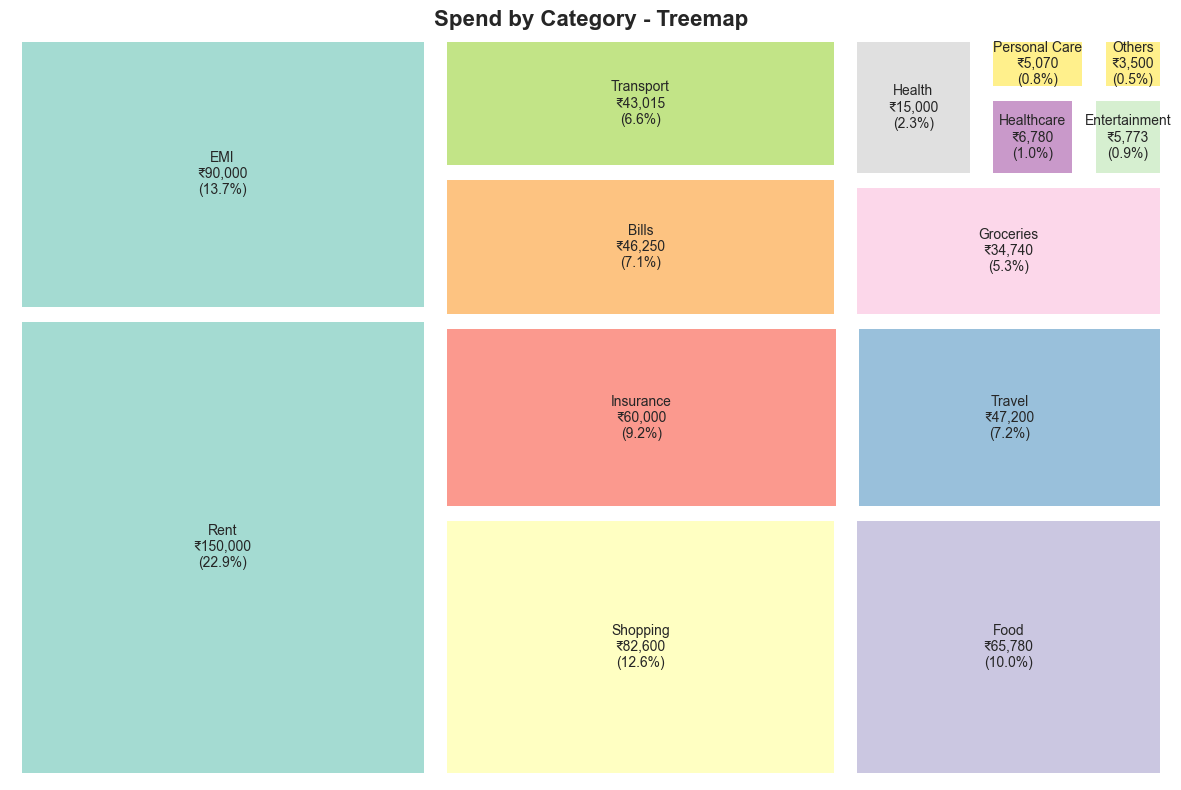

In [70]:
# Treemap using squarify (install: pip install squarify)
%pip install squarify
import numpy as np
import matplotlib.pyplot as plt
import squarify

# Prepare data
cat_spend = df[df['Is_Expense']].groupby('Category')['Amount'].agg(lambda x: abs(x).sum()).sort_values(ascending=False)
colors = plt.cm.Set3(np.linspace(0, 1, len(cat_spend)))

# Create treemap
plt.figure(figsize=(12, 8))
squarify.plot(sizes=cat_spend.values, 
              label=[f'{cat}\n₹{val:,.0f}\n({val/total_spend*100:.1f}%)' 
                     for cat, val in zip(cat_spend.index, cat_spend.values)],
              color=colors,
              alpha=0.8,
              pad=True)
plt.title('Spend by Category - Treemap', fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

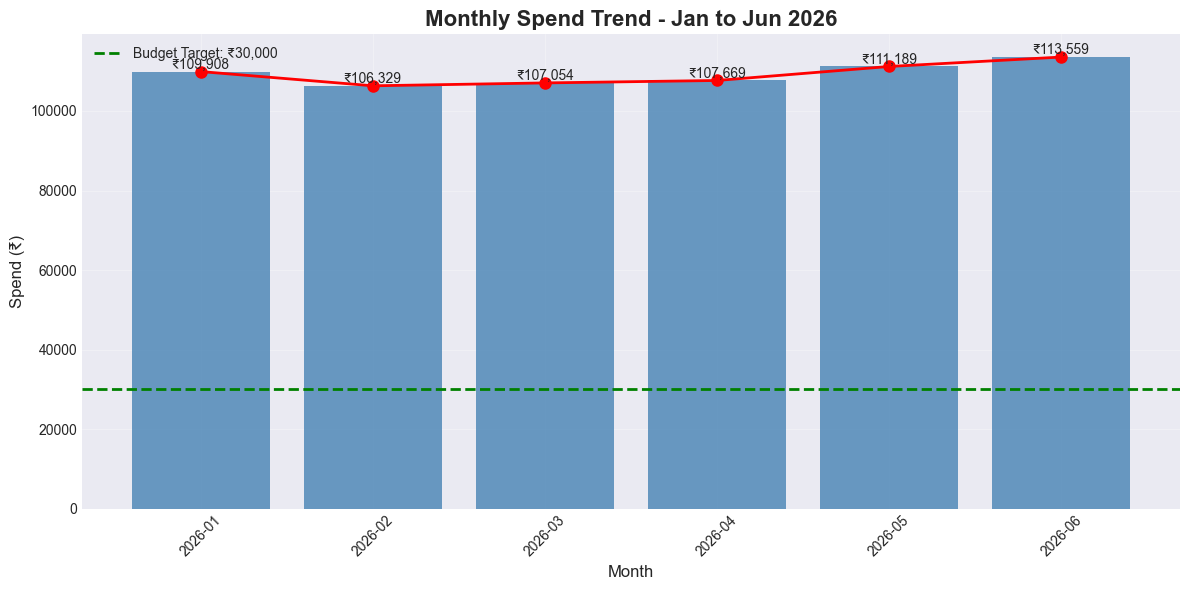

In [71]:
# Monthly trend
monthly_spend = df[df['Is_Expense']].groupby(df['Date'].dt.to_period('M'))['Amount'].agg(lambda x: abs(x).sum())
monthly_spend.index = monthly_spend.index.astype(str)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(monthly_spend.index, monthly_spend.values, color='steelblue', alpha=0.8)

# Add trend line
ax.plot(range(len(monthly_spend)), monthly_spend.values, 'r-', linewidth=2, marker='o', markersize=8)

# Add budget line (target)
budget_target = 30000
ax.axhline(y=budget_target, color='green', linestyle='--', linewidth=2, label=f'Budget Target: ₹{budget_target:,}')

# Customize
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Spend (₹)', fontsize=12)
ax.set_title('Monthly Spend Trend - Jan to Jun 2026', fontsize=16, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'₹{height:,.0f}',
            ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

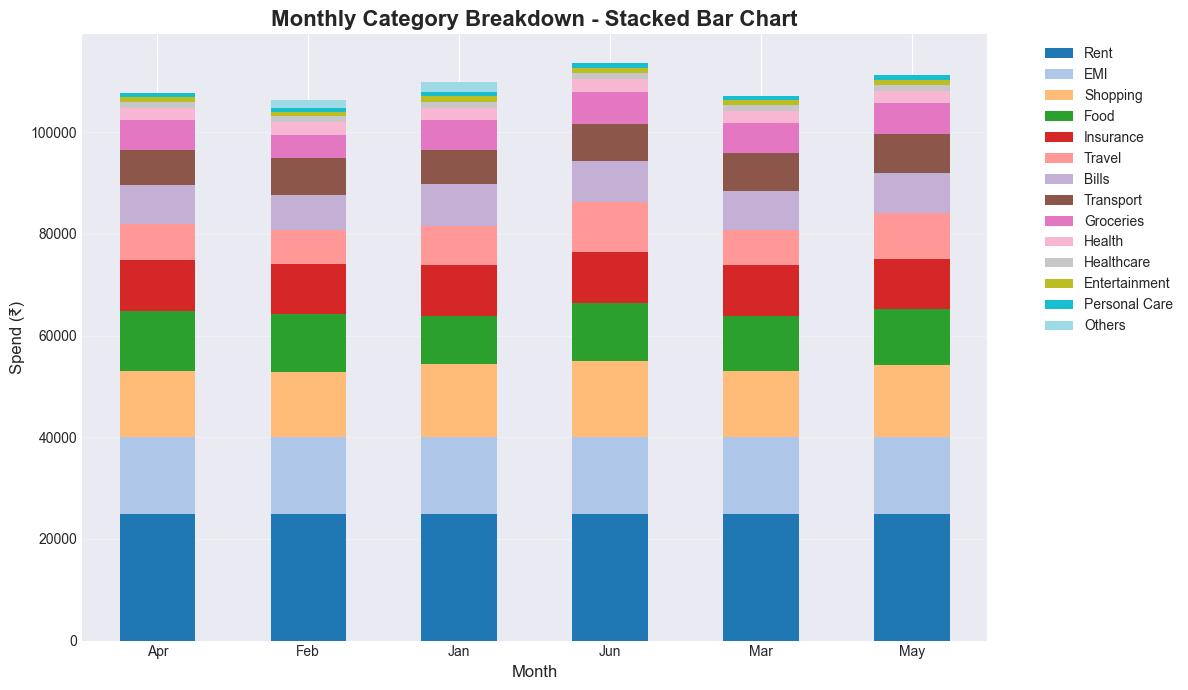

In [72]:
# Pivot table: Category by Month
pivot_expenses = df[df['Is_Expense']].pivot_table(
    values='Amount',
    index='Category',
    columns=df['Date'].dt.strftime('%b'),
    aggfunc=lambda x: abs(x).sum(),
    fill_value=0
)

# Sort categories by total spend
pivot_expenses['Total'] = pivot_expenses.sum(axis=1)
pivot_expenses = pivot_expenses.sort_values('Total', ascending=False)
pivot_expenses = pivot_expenses.drop('Total', axis=1)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
pivot_expenses.T.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')

ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Spend (₹)', fontsize=12)
ax.set_title('Monthly Category Breakdown - Stacked Bar Chart', fontsize=16, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3, axis='y')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

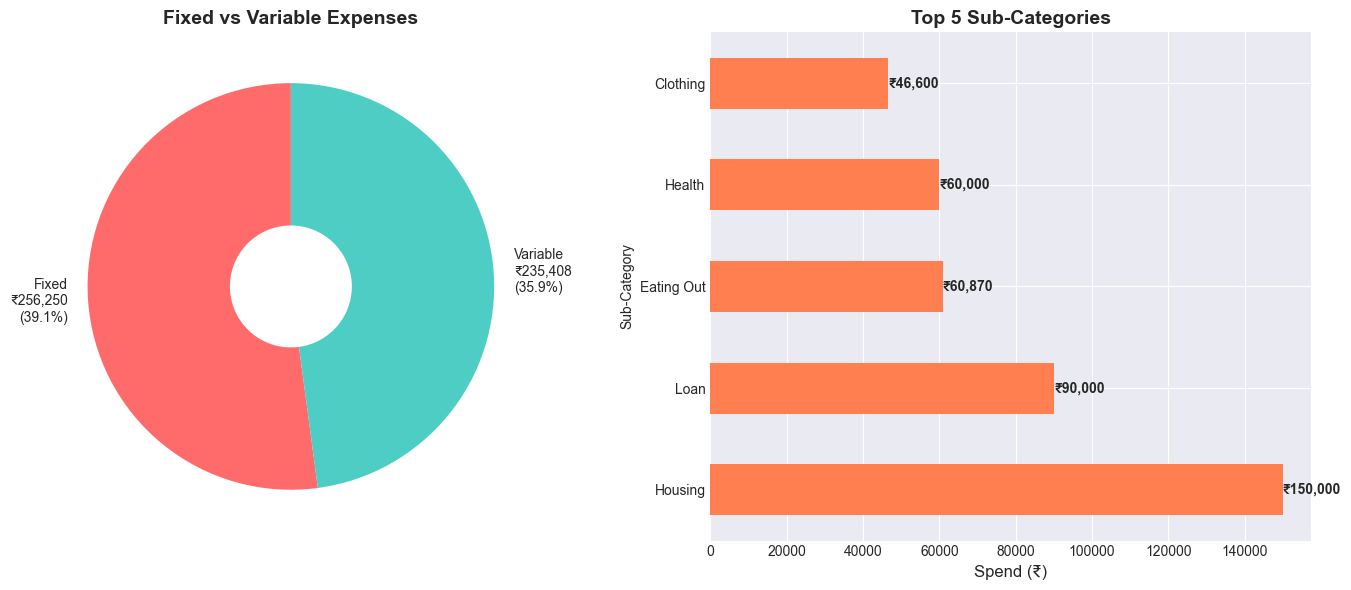

In [73]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Fixed vs Variable
fixed_var_data = [fixed_spend, variable_spend]
labels = [f'Fixed\n₹{fixed_spend:,.0f}\n({fixed_pct:.1f}%)',
          f'Variable\n₹{variable_spend:,.0f}\n({variable_pct:.1f}%)']
colors = ['#ff6b6b', '#4ecdc4']

# Donut Chart
wedges, texts, autotexts = ax1.pie(fixed_var_data, 
                                    labels=labels,
                                    colors=colors,
                                    autopct='',  # We added custom labels
                                    startangle=90,
                                    wedgeprops={'width': 0.7})
ax1.set_title('Fixed vs Variable Expenses', fontsize=14, fontweight='bold')

# Top 5 Sub-Categories
sub_cat_spend = df[df['Is_Expense']].groupby('Sub-Category')['Amount'].agg(lambda x: abs(x).sum()).sort_values(ascending=False).head(5)
sub_cat_spend.plot(kind='barh', ax=ax2, color='coral')
ax2.set_xlabel('Spend (₹)', fontsize=12)
ax2.set_title('Top 5 Sub-Categories', fontsize=14, fontweight='bold')

# Add value labels
for i, v in enumerate(sub_cat_spend.values):
    ax2.text(v + 100, i, f'₹{v:,.0f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

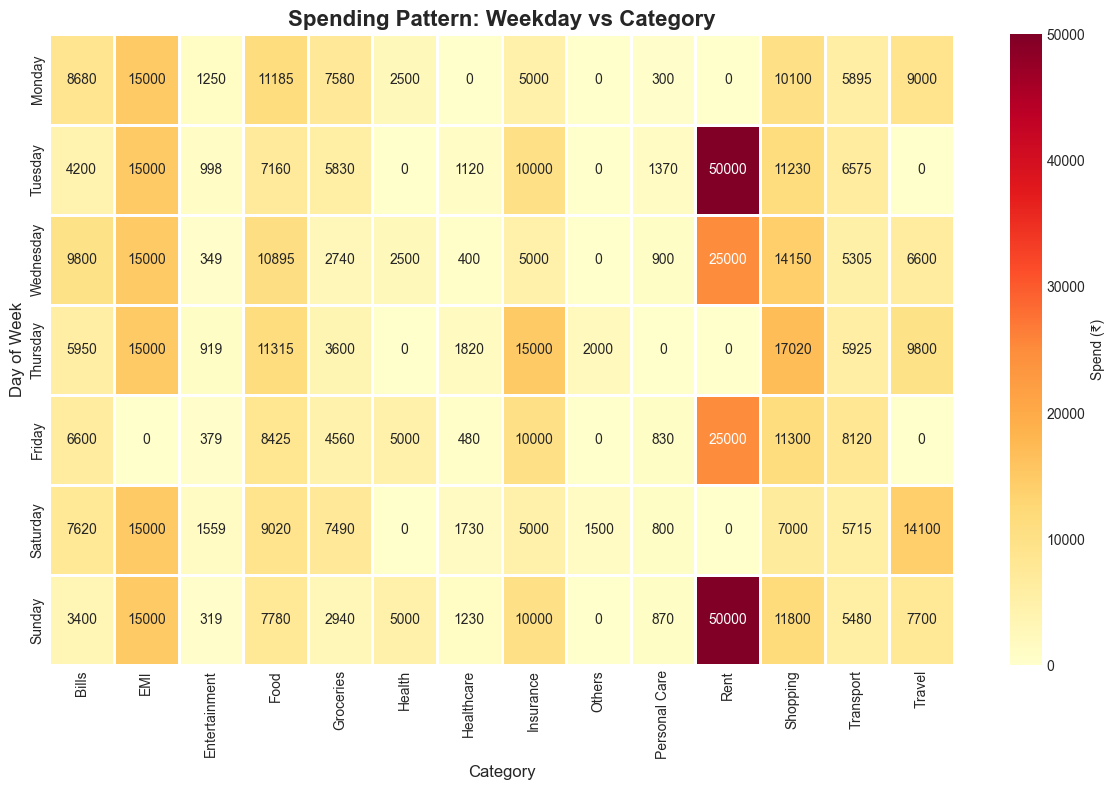

In [74]:
# Create pivot table for weekday × category
weekday_category = df[df['Is_Expense']].pivot_table(
    values='Amount',
    index='Weekday',
    columns='Category',
    aggfunc=lambda x: abs(x).sum(),
    fill_value=0
)

# Order weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_category = weekday_category.reindex(weekday_order)

# Create heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(weekday_category, 
            annot=True, 
            fmt='.0f',
            cmap='YlOrRd',
            linewidths=1,
            linecolor='white',
            cbar_kws={'label': 'Spend (₹)'})
plt.title('Spending Pattern: Weekday vs Category', fontsize=16, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.tight_layout()
plt.show()

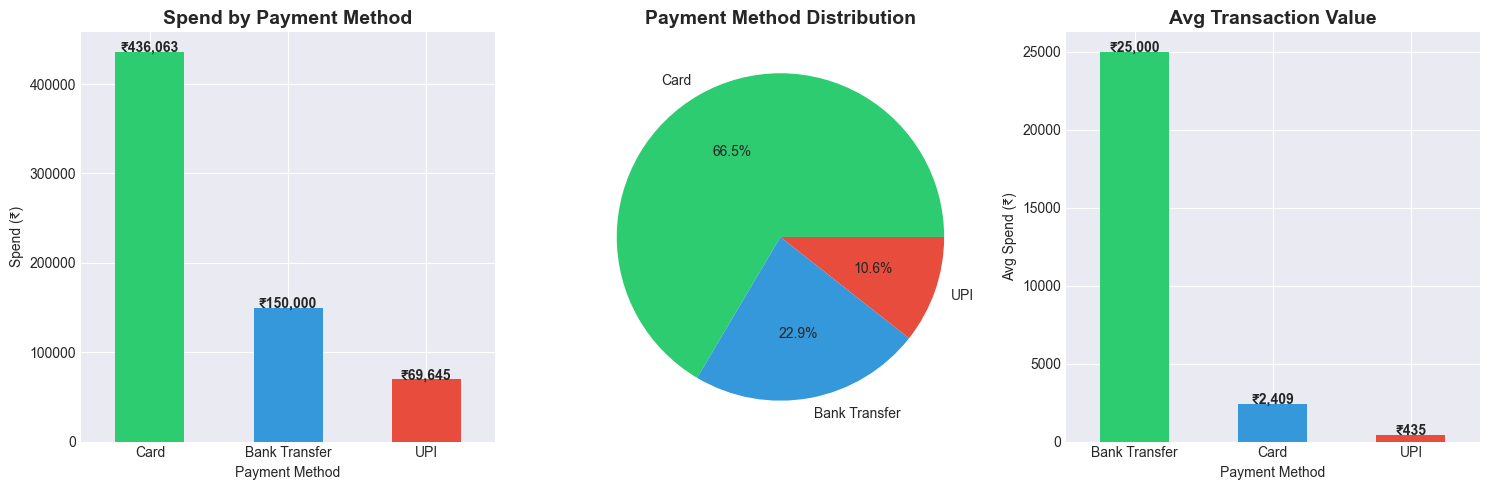

In [75]:
# Payment method analysis
payment_spend = df[df['Is_Expense']].groupby('Payment_Method')['Amount'].agg(lambda x: abs(x).sum()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Bar Chart
payment_spend.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
axes[0].set_title('Spend by Payment Method', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Payment Method')
axes[0].set_ylabel('Spend (₹)')
axes[0].tick_params(axis='x', rotation=0)

# Add value labels
for i, v in enumerate(payment_spend.values):
    axes[0].text(i, v + 100, f'₹{v:,.0f}', ha='center', fontweight='bold')

# 2. Pie Chart
axes[1].pie(payment_spend.values, 
            labels=payment_spend.index,
            autopct='%1.1f%%',
            colors=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
axes[1].set_title('Payment Method Distribution', fontsize=14, fontweight='bold')

# 3. Average Transaction Value by Payment Method
avg_payment = df[df['Is_Expense']].groupby('Payment_Method')['Amount'].agg(lambda x: abs(x).mean()).sort_values(ascending=False)
avg_payment.plot(kind='bar', ax=axes[2], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
axes[2].set_title('Avg Transaction Value', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Payment Method')
axes[2].set_ylabel('Avg Spend (₹)')
axes[2].tick_params(axis='x', rotation=0)

for i, v in enumerate(avg_payment.values):
    axes[2].text(i, v + 5, f'₹{v:,.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

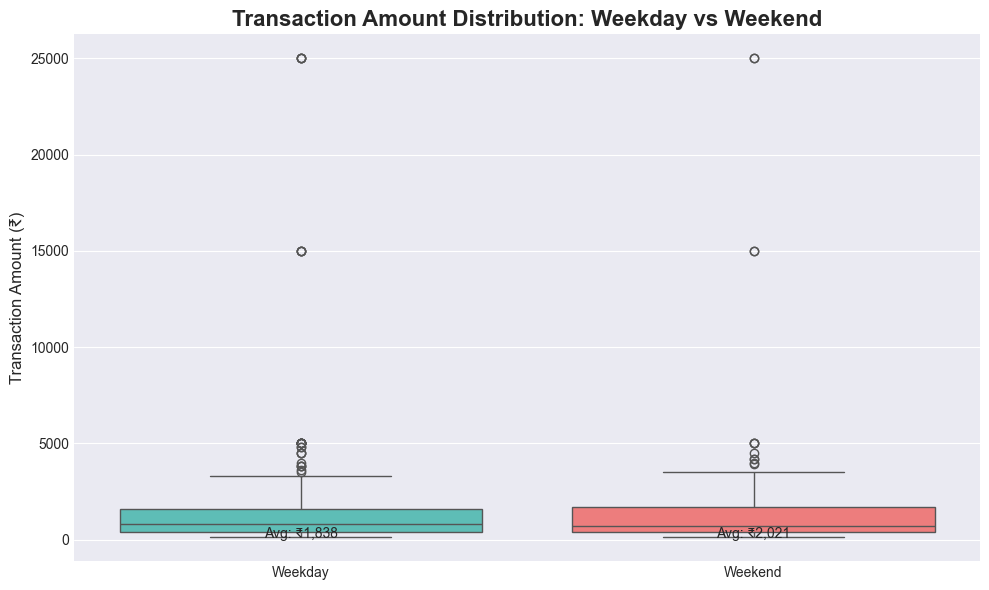

In [77]:
# Create Is_Weekend
df['Is_Weekend'] = df['Date'].dt.dayofweek >= 5

# Convert True/False to labels
df['Is_Weekend'] = df['Is_Weekend'].map({
    True: 'Weekend',
    False: 'Weekday'
})

# Keep only expenses
weekend_data = df[df['Is_Expense']].copy()

# Convert negative expenses to positive values
weekend_data['Amount_abs'] = weekend_data['Amount'].abs()

# Create boxplot
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    x='Is_Weekend',
    y='Amount_abs',
    data=weekend_data,
    palette=['#4ecdc4', '#ff6b6b']
)

ax.set_title(
    'Transaction Amount Distribution: Weekday vs Weekend',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('')
ax.set_ylabel('Transaction Amount (₹)', fontsize=12)

# Calculate averages
weekday_avg = weekend_data[
    weekend_data['Is_Weekend'] == 'Weekday'
]['Amount_abs'].mean()

weekend_avg = weekend_data[
    weekend_data['Is_Weekend'] == 'Weekend'
]['Amount_abs'].mean()

# Add averages
ax.text(0, 100, f'Avg: ₹{weekday_avg:,.0f}', ha='center')
ax.text(1, 100, f'Avg: ₹{weekend_avg:,.0f}', ha='center')

plt.tight_layout()
plt.show()

Correlation Matrix:
                        Total_Spend  Unique_Payment_Methods  \
Total_Spend                1.000000                0.239858   
Unique_Payment_Methods     0.239858                1.000000   
Unique_Categories          0.095382                0.129641   
Weekday_Num                0.021667               -0.024764   

                        Unique_Categories  Weekday_Num  
Total_Spend                      0.095382     0.021667  
Unique_Payment_Methods           0.129641    -0.024764  
Unique_Categories                1.000000    -0.052205  
Weekday_Num                     -0.052205     1.000000  


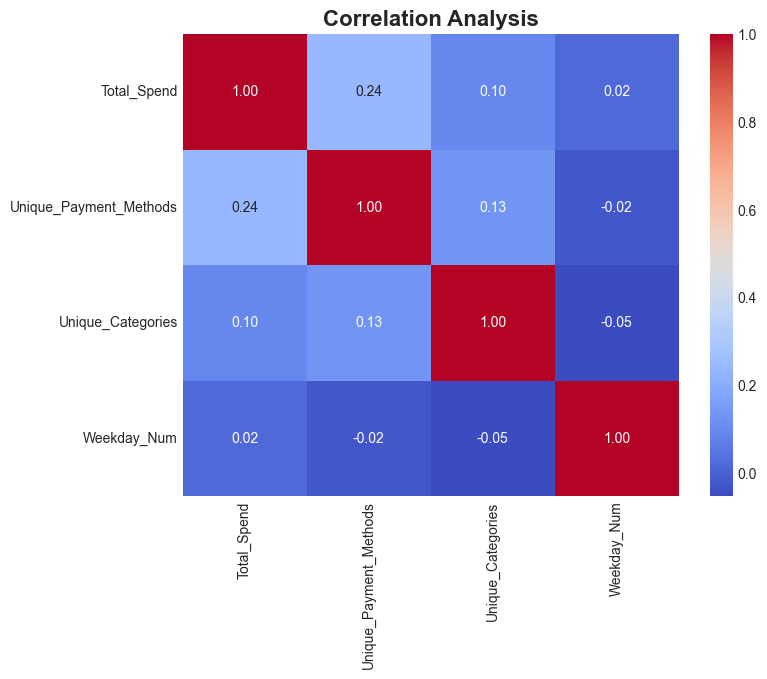

In [78]:
# Create daily aggregated data
daily_data = df[df['Is_Expense']].groupby('Date').agg({
    'Amount': lambda x: abs(x).sum(),
    'Payment_Method': 'nunique',
    'Category': 'nunique'
}).reset_index()

# Rename columns
daily_data.columns = ['Date', 'Total_Spend', 'Unique_Payment_Methods', 'Unique_Categories']

# Add day of week
daily_data['Weekday'] = daily_data['Date'].dt.day_name()
daily_data['Weekday_Num'] = daily_data['Date'].dt.weekday
daily_data['Is_Weekend'] = daily_data['Weekday_Num'] >= 5

# Correlation
correlation_matrix = daily_data[['Total_Spend', 'Unique_Payment_Methods', 'Unique_Categories', 'Weekday_Num']].corr()
print("Correlation Matrix:")
print(correlation_matrix)

# Visualize correlation
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Analysis', fontsize=16, fontweight='bold')
plt.show()

In [79]:
# Calculate month-over-month growth
monthly_growth = monthly_spend.pct_change() * 100

print("Month-over-Month Growth:")
for month, growth in zip(monthly_growth.index, monthly_growth.values):
    if not pd.isna(growth):
        arrow = '↑' if growth > 0 else '↓'
        color = '🔴' if growth > 0 else '🟢'
        print(f"{month}: {arrow} {growth:+.1f}% {color}")

Month-over-Month Growth:
2026-02: ↓ -3.3% 🟢
2026-03: ↑ +0.7% 🔴
2026-04: ↑ +0.6% 🔴
2026-05: ↑ +3.3% 🔴
2026-06: ↑ +2.1% 🔴


In [80]:
# Top 5 spending days
top_spending_days = df[df['Is_Expense']].groupby('Date').agg({
    'Amount': lambda x: abs(x).sum()
}).sort_values('Amount', ascending=False).head(10)

print("\n📊 Top 10 Spending Days:")
for date, row in top_spending_days.iterrows():
    weekday = date.strftime('%A')
    print(f"{date.strftime('%d-%b-%Y')} ({weekday}): ₹{row['Amount']:,.0f}")


📊 Top 10 Spending Days:
04-Jan-2026 (Sunday): ₹28,400
03-Feb-2026 (Tuesday): ₹25,199
03-Apr-2026 (Friday): ₹25,199
03-Mar-2026 (Tuesday): ₹25,199
03-May-2026 (Sunday): ₹25,199
03-Jun-2026 (Wednesday): ₹25,199
25-Jan-2026 (Sunday): ₹15,280
25-Jun-2026 (Thursday): ₹15,270
25-May-2026 (Monday): ₹15,260
25-Feb-2026 (Wednesday): ₹15,250


In [81]:
# Category statistics
category_stats = df[df['Is_Expense']].groupby('Category')['Amount'].agg([
    ('Total', lambda x: abs(x).sum()),
    ('Count', 'count'),
    ('Avg', lambda x: abs(x).mean()),
    ('Min', lambda x: abs(x).min()),
    ('Max', lambda x: abs(x).max()),
    ('Std', lambda x: abs(x).std())
]).sort_values('Total', ascending=False)

category_stats['% of Total'] = (category_stats['Total'] / total_spend) * 100
print("Category Statistics:")
display(category_stats)

Category Statistics:


,Total,Count,Avg,Min,Max,Std,% of Total
Category,,,,,,,
Rent,150000,6,25000.000000,25000,25000,0.000000,22.876036
EMI,90000,6,15000.000000,15000,15000,0.000000,13.725622
Shopping,82600,31,2664.516129,350,4800,1335.187474,12.597071
Food,65780,104,632.500000,150,2500,491.384017,10.031904
Insurance,60000,12,5000.000000,5000,5000,0.000000,9.150415
Travel,47200,12,3933.333333,2800,5000,707.535201,7.198326
Bills,46250,35,1321.428571,500,3400,880.461586,7.053445
Transport,43015,56,768.125000,140,1700,582.353035,6.560085
Groceries,34740,35,992.571429,400,1500,322.256227,5.298090


In [86]:
# ==========================================
# KPI CALCULATIONS
# ==========================================

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Create Is_Expense if not already created
df['Is_Expense'] = df['Amount'] < 0


# ------------------------------------------
# 1. TOTAL SPEND
# ------------------------------------------

total_spend = (
    df.loc[df['Is_Expense'], 'Amount']
      .abs()
      .sum()
)


# ------------------------------------------
# 2. TOTAL INCOME
# ------------------------------------------

total_income = (
    df.loc[~df['Is_Expense'], 'Amount']
      .sum()
)


# ------------------------------------------
# 3. SAVINGS
# ------------------------------------------

savings = total_income - total_spend


# ------------------------------------------
# 4. SAVINGS RATE
# ------------------------------------------

savings_rate = (
    savings / total_income * 100
    if total_income != 0
    else 0
)


# ------------------------------------------
# 5. MONTHLY SPENDING
# ------------------------------------------

monthly_spend = (
    df.loc[df['Is_Expense']]
      .groupby(
          df.loc[df['Is_Expense'], 'Date'].dt.to_period('M')
      )['Amount']
      .apply(lambda x: x.abs().sum())
      .sort_index()
)

avg_monthly = monthly_spend.mean()


# ------------------------------------------
# 6. DAILY AVERAGE SPENDING
# ------------------------------------------

daily_spend = (
    df.loc[df['Is_Expense']]
      .groupby(
          df.loc[df['Is_Expense'], 'Date'].dt.date
      )['Amount']
      .apply(lambda x: x.abs().sum())
)

daily_avg = daily_spend.mean()


# ------------------------------------------
# 7. CATEGORY SPENDING
# ------------------------------------------

cat_spend = (
    df.loc[df['Is_Expense']]
      .groupby('Category')['Amount']
      .apply(lambda x: x.abs().sum())
      .sort_values(ascending=False)
)

top_category = (
    cat_spend.idxmax()
    if not cat_spend.empty
    else 'N/A'
)


# ------------------------------------------
# 8. FIXED VS VARIABLE
# ------------------------------------------

# If your dataframe has Expense_Type column
if 'Expense_Type' in df.columns:

    fixed_spend = (
        df.loc[
            (df['Is_Expense']) &
            (df['Expense_Type'].str.strip().str.lower() == 'fixed'),
            'Amount'
        ]
        .abs()
        .sum()
    )

    variable_spend = (
        df.loc[
            (df['Is_Expense']) &
            (df['Expense_Type'].str.strip().str.lower() == 'variable'),
            'Amount'
        ]
        .abs()
        .sum()
    )

else:
    # If Expense_Type doesn't exist
    fixed_spend = 0
    variable_spend = total_spend


# ------------------------------------------
# 9. FIXED / VARIABLE PERCENTAGES
# ------------------------------------------

fixed_pct = (
    fixed_spend / total_spend * 100
    if total_spend != 0
    else 0
)

variable_pct = (
    variable_spend / total_spend * 100
    if total_spend != 0
    else 0
)


# ------------------------------------------
# 10. DONUT CHART DATA
# ------------------------------------------

fixed_var_data = [
    fixed_spend,
    variable_spend
]


# ------------------------------------------
# CHECK RESULTS
# ------------------------------------------

print("========== KPI RESULTS ==========")
print(f"Total Spend       : ₹{total_spend:,.0f}")
print(f"Total Income      : ₹{total_income:,.0f}")
print(f"Savings           : ₹{savings:,.0f}")
print(f"Savings Rate      : {savings_rate:.1f}%")
print(f"Average Monthly   : ₹{avg_monthly:,.0f}")
print(f"Daily Average     : ₹{daily_avg:,.0f}")
print(f"Top Category      : {top_category}")
print(f"Fixed Spend       : ₹{fixed_spend:,.0f}")
print(f"Variable Spend    : ₹{variable_spend:,.0f}")
print(f"Fixed %           : {fixed_pct:.1f}%")
print(f"Variable %        : {variable_pct:.1f}%")

========== KPI RESULTS ==========
Total Spend       : ₹655,708
Total Income      : ₹920,000
Savings           : ₹264,292
Savings Rate      : 28.7%
Average Monthly   : ₹109,285
Daily Average     : ₹3,643
Top Category      : Rent
Fixed Spend       : ₹0
Variable Spend    : ₹655,708
Fixed %           : 0.0%
Variable %        : 100.0%
